In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# Create a blank binary image
image = np.zeros((200, 200), dtype=np.uint8)

cv2.rectangle(image, (30, 30), (90, 90), 255, -1)

cv2.circle(image, (140, 140), 30, 255, -1)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(200, 200), dtype=uint8)

In [7]:
kernel = np.ones((5, 5), np.uint8)

In [8]:
erosion = cv2.erode(image, kernel, iterations=2)

dilation = cv2.dilate(image, kernel, iterations=1)

opening = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)

closing = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

gradient = cv2.morphologyEx(image, cv2.MORPH_GRADIENT, kernel)

tophat = cv2.morphologyEx(image, cv2.MORPH_TOPHAT, kernel)

blackhat = cv2.morphologyEx(image, cv2.MORPH_BLACKHAT, kernel)

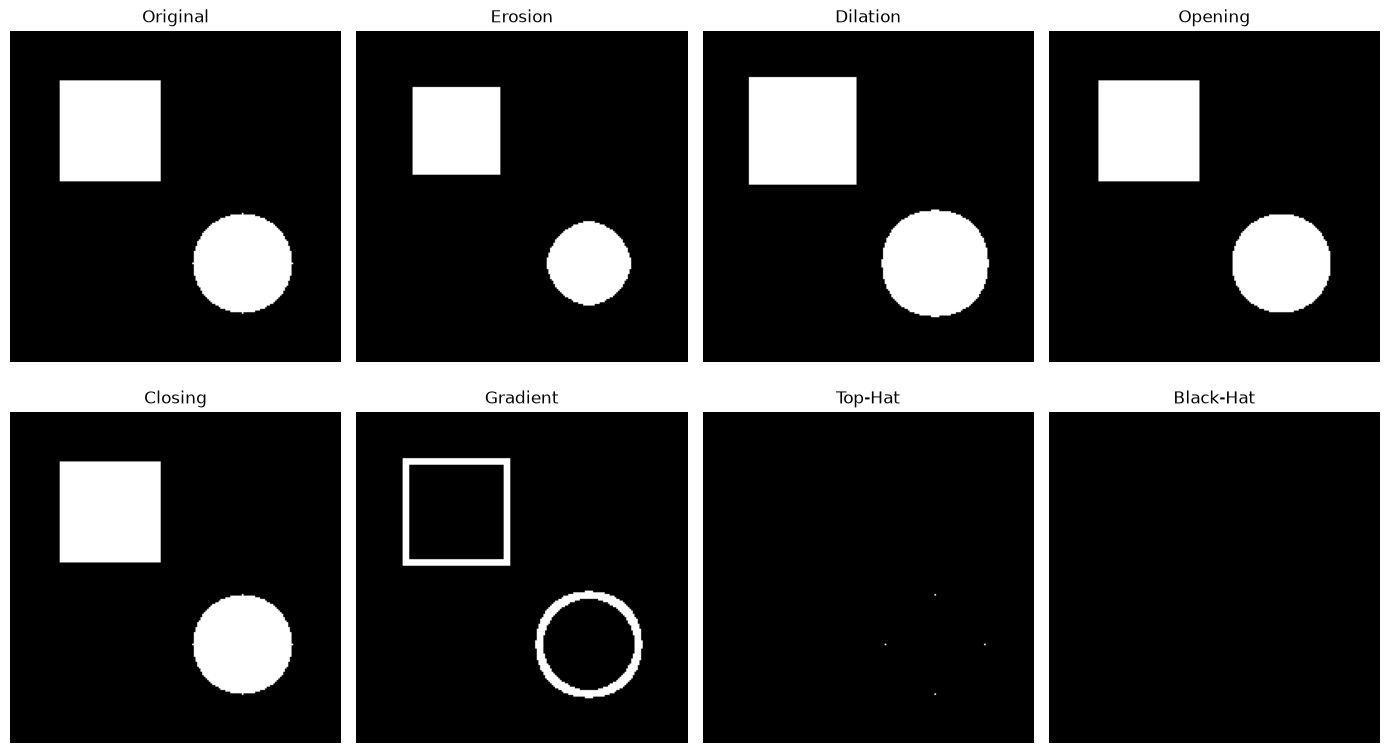

In [9]:
titles = ["Original","Erosion","Dilation","Opening","Closing","Gradient","Top-Hat","Black-Hat"]

images = [
    image,
    erosion,
    dilation,
    opening,
    closing,
    gradient,
    tophat,
    blackhat
]

plt.figure(figsize=(14, 8))

for i in range(len(images)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

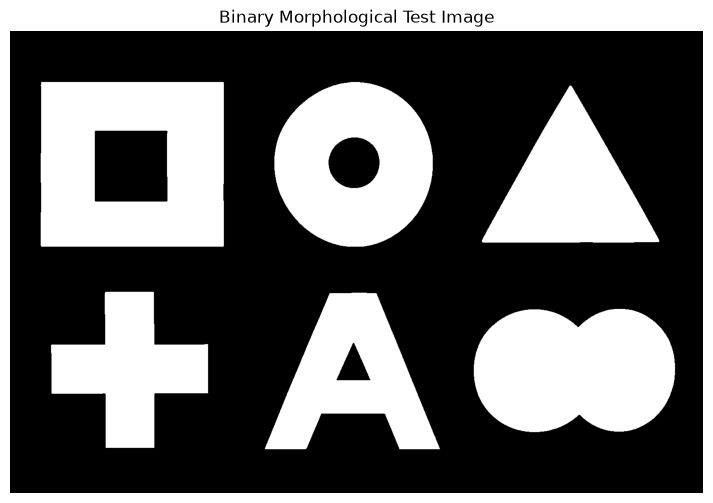

In [10]:
image = cv2.imread(
    r"C:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\Images\morphology_test.png",
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    raise FileNotFoundError("Check the image path.")

_, binary = cv2.threshold(
    image,
    127,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(10, 6))
plt.imshow(binary, cmap="gray")
plt.title("Binary Morphological Test Image")
plt.axis("off")
plt.show()

In [11]:
kernel = np.ones((3, 3), np.uint8)

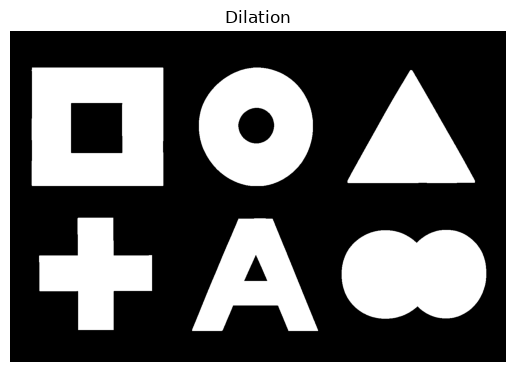

In [12]:
dilation = cv2.dilate(binary, kernel, iterations=1)

plt.imshow(dilation, cmap="gray")
plt.title("Dilation")
plt.axis("off")
plt.show()

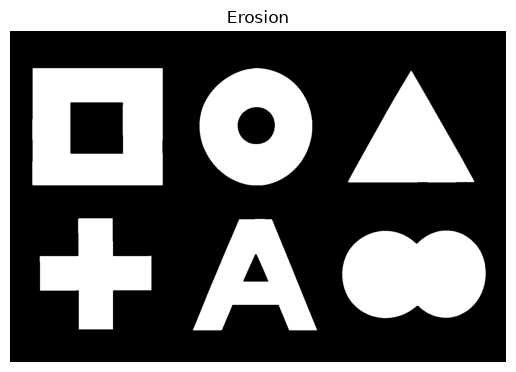

In [13]:
erosion = cv2.erode(binary, kernel, iterations=1)

plt.imshow(erosion, cmap="gray")
plt.title("Erosion")
plt.axis("off")
plt.show()

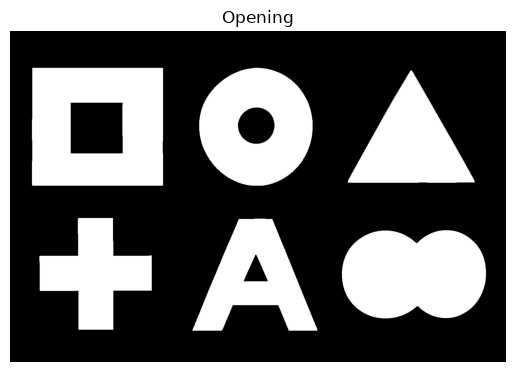

In [14]:
opening = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel
)

plt.imshow(opening, cmap="gray")
plt.title("Opening")
plt.axis("off")
plt.show()

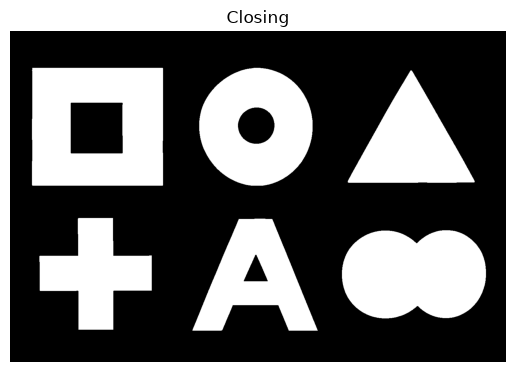

In [15]:
closing = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    kernel
)

plt.imshow(closing, cmap="gray")
plt.title("Closing")
plt.axis("off")
plt.show()

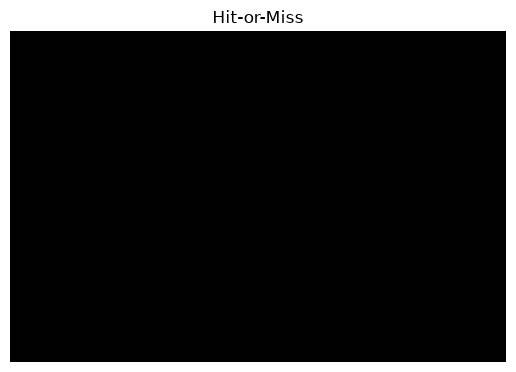

In [16]:
hitmiss_kernel = np.array([
    [0, -1, 0],
    [-1, 1, -1],
    [0, -1, 0]
], dtype=np.int8)

hit_or_miss = cv2.morphologyEx(
    binary,
    cv2.MORPH_HITMISS,
    hitmiss_kernel
)

plt.imshow(hit_or_miss, cmap="gray")
plt.title("Hit-or-Miss")
plt.axis("off")
plt.show()

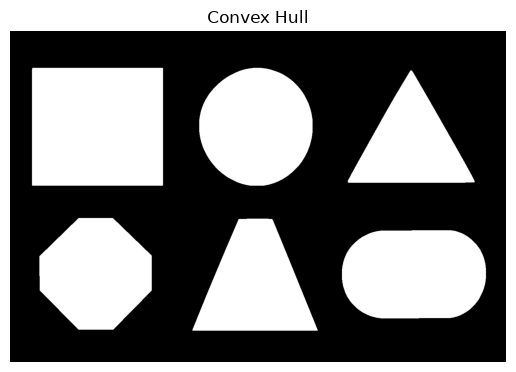

In [17]:
convex_hull_image = np.zeros_like(binary)

contours, _ = cv2.findContours(
    binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

for contour in contours:
    if cv2.contourArea(contour) > 0:
        hull = cv2.convexHull(contour)

        cv2.drawContours(
            convex_hull_image,
            [hull],
            -1,
            255,
            thickness=cv2.FILLED
        )

plt.imshow(convex_hull_image, cmap="gray")
plt.title("Convex Hull")
plt.axis("off")
plt.show()

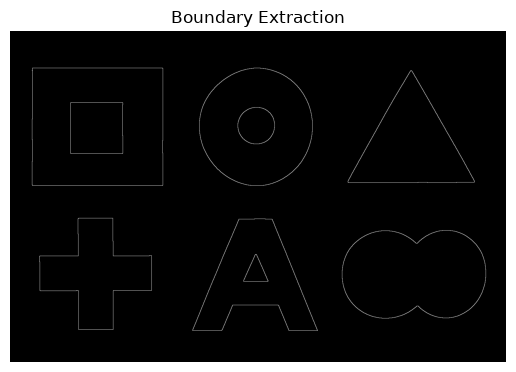

In [18]:
boundary = cv2.subtract(
    binary,
    cv2.erode(binary, kernel, iterations=1)
)

plt.imshow(boundary, cmap="gray")
plt.title("Boundary Extraction")
plt.axis("off")
plt.show()

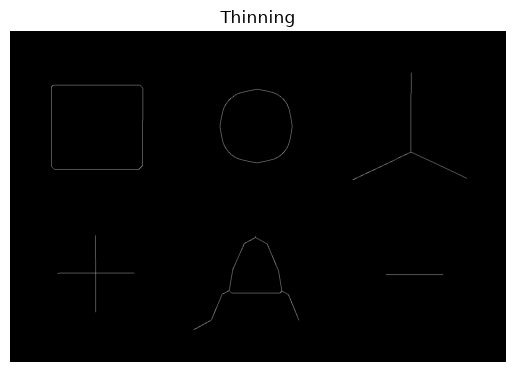

In [19]:
if not hasattr(cv2, "ximgproc"):
    raise ImportError(
        "Install opencv-contrib-python and restart the kernel."
    )

thinning = cv2.ximgproc.thinning(
    binary,
    thinningType=cv2.ximgproc.THINNING_ZHANGSUEN
)

plt.imshow(thinning, cmap="gray")
plt.title("Thinning")
plt.axis("off")
plt.show()

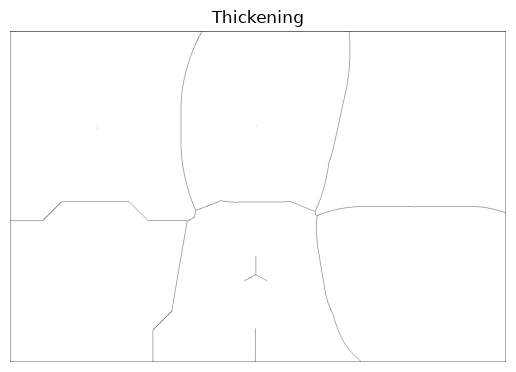

In [20]:
thickening = cv2.ximgproc.thinning(
    cv2.bitwise_not(binary),
    thinningType=cv2.ximgproc.THINNING_ZHANGSUEN
)

thickening = cv2.bitwise_not(thickening)

plt.imshow(thickening, cmap="gray")
plt.title("Thickening")
plt.axis("off")
plt.show()

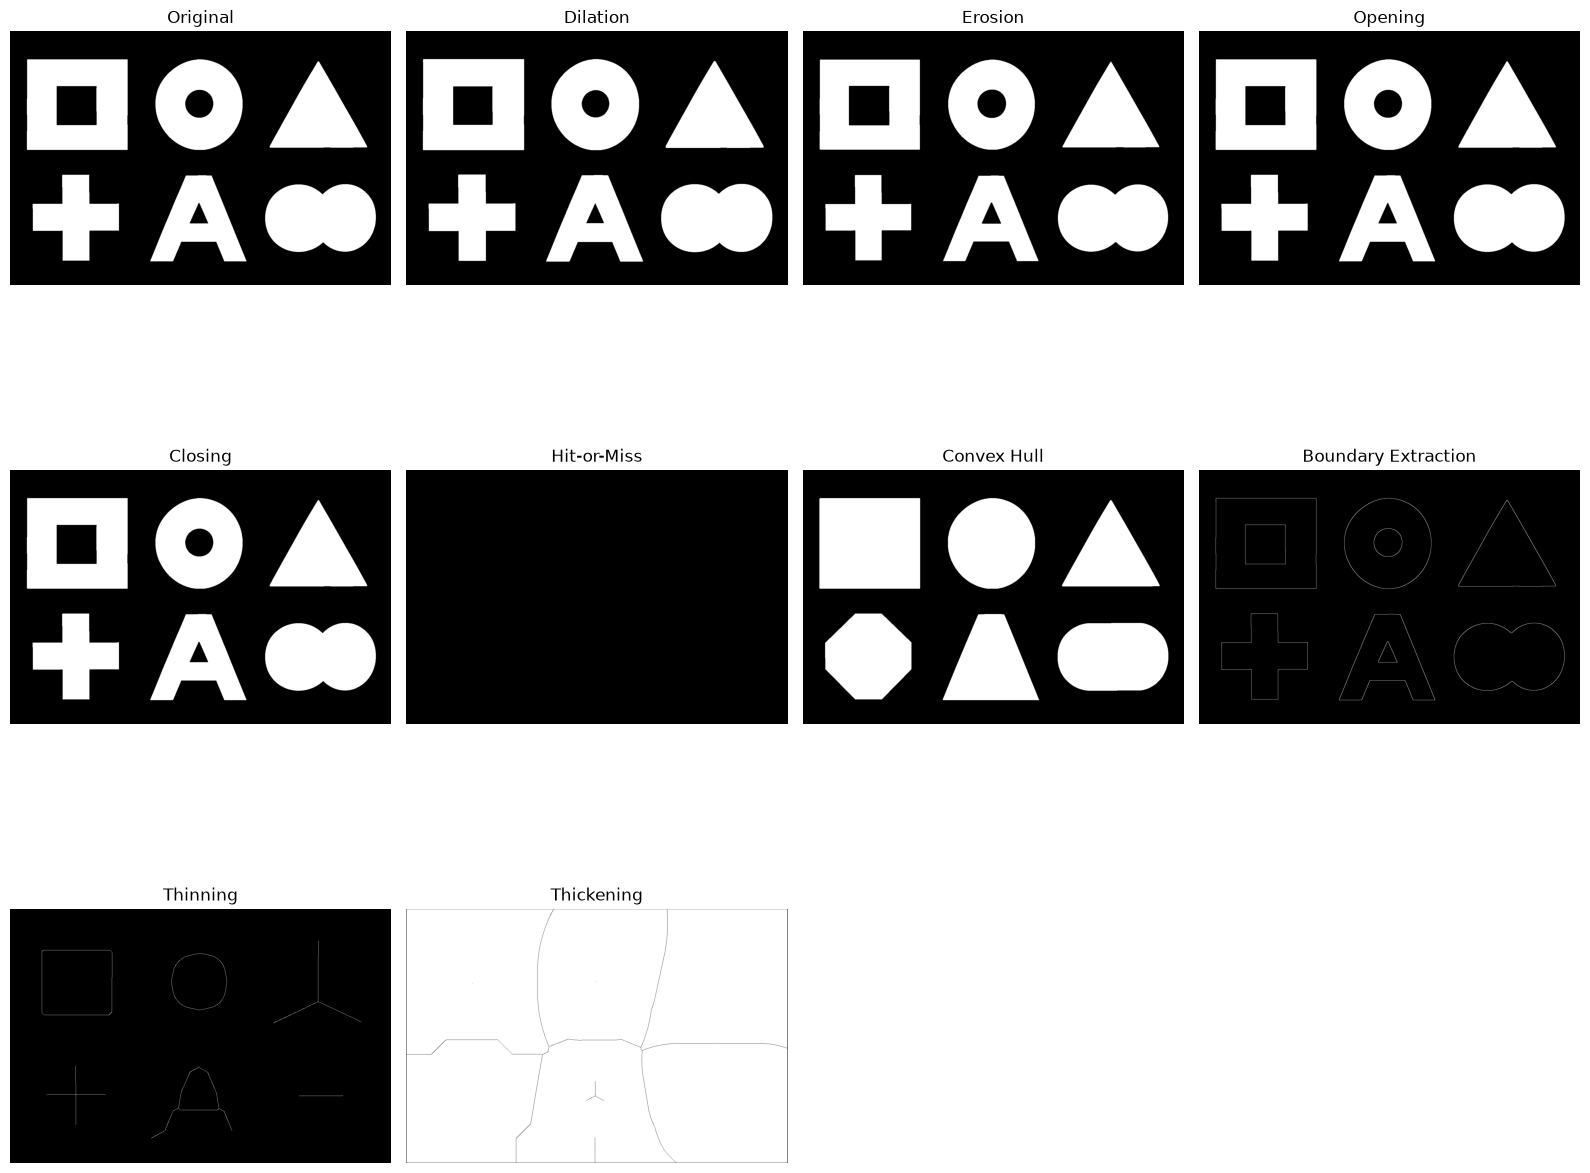

In [31]:
titles = ["Original","Dilation","Erosion","Opening","Closing","Hit-or-Miss","Convex Hull",
    "Boundary Extraction","Thinning","Thickening"]
images = [
    binary,
    dilation,
    erosion,
    opening,
    closing,
    hit_or_miss,
    convex_hull_image,
    boundary,
    thinning,
    thickening
]
plt.figure(figsize=(16, 14))
for i, (title, result) in enumerate(zip(titles, images)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()